In [1]:
from tensorflow import keras
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.preprocessing.image import load_img
from keras.models import load_model
from tensorflow.keras.layers import Conv2D, BatchNormalization, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from keras.layers import Activation
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

In [2]:
images = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3815s 22us/step


In [4]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

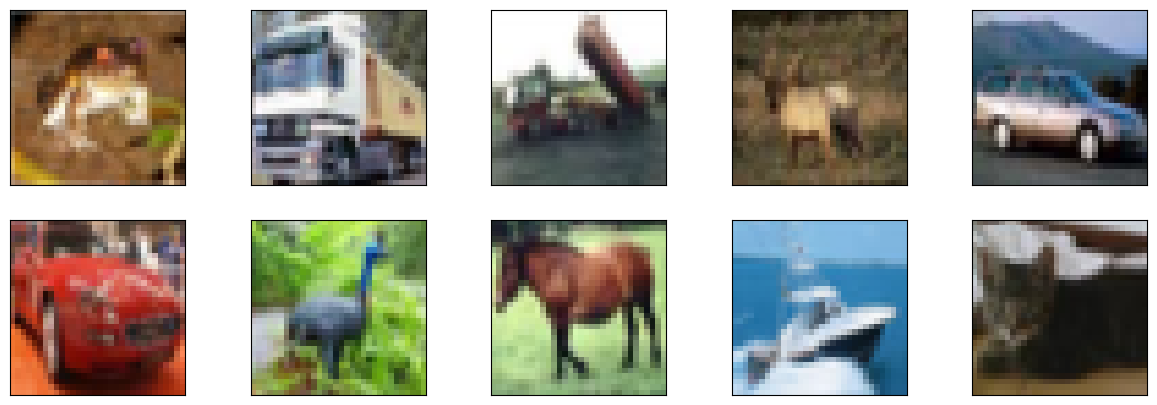

In [5]:
fig = plt.figure(figsize=(15,5))
for i in range(10):
  ax = fig.add_subplot(2,5,i+1,xticks=[],yticks=[])
  ax.imshow(X_train[i])

In [6]:
# Image Processing: Normalize pixel values to be between 0 and 1
X_train = X_train / 255.0
X_test = X_test / 255.0

In [7]:
#one hot encoded
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, num_classes=10)
y_test=to_categorical(y_test,10)

# Build The CNN Architecture

In [8]:
AlexNet = Sequential()

In [10]:
#1st Conv layer

AlexNet.add(Conv2D(filters=96,input_shape=(32,32,3),kernel_size=(11,11),strides=(4,4),padding="same"))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation('relu'))
AlexNet.add(MaxPooling2D(pool_size=(2,2),strides=(2,2),padding="same"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
#2nd Conv layer
AlexNet.add(Conv2D(filters=256,kernel_size=(5,5),strides=(1,1),padding="same"))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation('relu'))
AlexNet.add(MaxPooling2D(pool_size=(2,2),strides=(2,2),padding="same"))

In [12]:
#3rd Conv layer
AlexNet.add(Conv2D(filters=384,kernel_size=(3,3),strides=(1,1),padding="same"))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation('relu'))


In [13]:
#4th layer
AlexNet.add(Conv2D(filters=256,kernel_size=(3,3),strides=(1,1),padding="same"))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation('relu'))

In [14]:
#5th Conv layer
AlexNet.add(Conv2D(filters=256,kernel_size=(3,3),strides=(1,1),padding="same"))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation('relu'))
AlexNet.add(MaxPooling2D(pool_size=(2,2),strides=(2,2),padding="same"))

In [15]:
AlexNet.add(Flatten())

# Fully Connected

In [16]:
#1st Fc

AlexNet.add(   Dense(4096, input_shape=(32,32,3,))   )
AlexNet.add(BatchNormalization())
AlexNet.add(Activation("relu"))
AlexNet.add(Dropout(0.4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
#2nd Fc
AlexNet.add(Dense(4096))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation("relu"))
AlexNet.add(Dropout(0.4))

In [18]:
#3rd Fc
AlexNet.add(Dense(1000))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation("relu"))
AlexNet.add(Dropout(0.4))

In [19]:
#4th fc (Output)
AlexNet.add(Dense(10))
AlexNet.add(BatchNormalization())
AlexNet.add(Activation("softmax"))


In [20]:
AlexNet.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 96)       │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 8, 8, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 256)      │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 2, 2, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 2, 2, 384)      │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 2, 2, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 2, 2, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │     1,052,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 4096)           │             

 Total params: 24,992,586 (95.34 MB)

 Trainable params: 24,971,686 (95.26 MB)

 Non-trainable params: 20,900 (81.64 KB)

In [ ]:
!pip install visualkeras

import visualkeras
visualkeras.layered_view(AlexNet,legend=True)

In [21]:
AlexNet.compile(loss=keras.losses.categorical_crossentropy,optimizer="adam",metrics=["accuracy"])

In [22]:
history = AlexNet.fit(X_train,y_train,batch_size=32,epochs=3,verbose=2,shuffle=True)

Epoch 1/3
1563/1563 - 742s - 475ms/step - accuracy: 0.4242 - loss: 1.6008
Epoch 2/3
1563/1563 - 740s - 473ms/step - accuracy: 0.5239 - loss: 1.3502
Epoch 3/3
1563/1563 - 741s - 474ms/step - accuracy: 0.5763 - loss: 1.2181


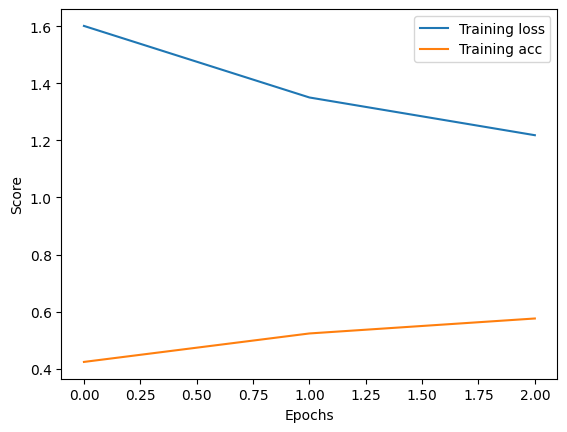

In [23]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'],label="Training loss")
plt.plot(history.history['accuracy'],label="Training acc")
plt.xlabel("Epochs")
plt.ylabel("Score")
plt.legend()